# Đề tài 8 — PCA, SVD và xấp xỉ hạng thấp
## Notebook 2/3 — Phần B: Chứng minh lý thuyết và kiểm chứng số

Mỗi mục gồm **phát biểu** (đủ giả thiết) → **chứng minh** → **ô kiểm chứng số**. Bản LaTeX của toàn bộ chứng minh nằm trong tài liệu hướng dẫn đi kèm (dùng trực tiếp cho báo cáo).

Notebook này import các cài đặt từ `src/pca_core.py` (xuất từ Notebook 1), không định nghĩa lại thuật toán.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_wine

for p in ["../src", "src", "."]:                      # tìm thư mục chứa pca_core.py
    if os.path.exists(os.path.join(p, "pca_core.py")):
        sys.path.insert(0, os.path.abspath(p)); break
from pca_core import pca_svd, LinearAutoencoder, PCAMonitor, mean_std

SEED, N_RUNS = 42, 5
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

X_wine, _ = load_wine(return_X_y=True)
Xw = (X_wine - X_wine.mean(0)) / X_wine.std(0, ddof=1)     # Wine chuẩn hóa, dùng ở B.1, B.3

---
# Phần B — Chứng minh lý thuyết

Mỗi mục gồm: **phát biểu** (đủ giả thiết) → **chứng minh** → **kiểm chứng số**. Ký hiệu $\langle\cdot,\cdot\rangle$, $\|\cdot\|$ là tích vô hướng và chuẩn Euclid; $\|M\|_F^2=\operatorname{tr}(M^\top M)=\sum_{ij}M_{ij}^2$.

**Hai sự kiện dùng nhiều lần.**
- **(F1) Phép chiếu trực giao.** Nếu $U\in\mathbb R^{d\times k}$ có $U^\top U=I_k$ thì $P=UU^\top$ thỏa $P^\top=P$, $P^2=P$; với mọi $x$: $x-Px\perp Px$ (vì $U^\top(x-UU^\top x)=0$), nên $\|x\|^2=\|Px\|^2+\|x-Px\|^2$ (Pythagoras) và $\|Px\|^2=\|U^\top x\|^2\le\|x\|^2$.
- **(F2) Vết bất biến hoán vị vòng:** $\operatorname{tr}(ABC)=\operatorname{tr}(CAB)$.

---
## B.1 Cực đại phương sai ⇔ cực tiểu sai số tái tạo; định lý Ky Fan

**Phát biểu.** Cho $\Sigma\in\mathbb R^{d\times d}$ đối xứng với trị riêng $\lambda_1\ge\dots\ge\lambda_d$ và vector riêng trực chuẩn $v_1,\dots,v_d$; $1\le k\le d$, $V_k=[v_1,\dots,v_k]$.
1. *(Ky Fan)* $\displaystyle\max_{U\in\mathbb R^{d\times k},\,U^\top U=I_k}\operatorname{tr}(U^\top\Sigma U)=\sum_{i=1}^k\lambda_i$, đạt tại $U=V_k$. Nếu thêm $\lambda_k>\lambda_{k+1}$ thì giá trị lớn nhất đạt **khi và chỉ khi** $\operatorname{span}(U)=\operatorname{span}(V_k)$. Trường hợp $k=1$: $\max_{\|u\|=1}u^\top\Sigma u=\lambda_1$ (thương Rayleigh).
2. *(Tương đương)* Với dữ liệu đã quy tâm $x_1,\dots,x_n$ và $\Sigma=\frac1{n-1}\sum_i x_ix_i^\top$, mọi $U$ có $U^\top U=I_k$ thỏa
$$\underbrace{\frac1{n-1}\sum_{i=1}^n\|x_i-UU^\top x_i\|^2}_{\text{sai số tái tạo}}=\operatorname{tr}\Sigma-\underbrace{\operatorname{tr}(U^\top\Sigma U)}_{\text{phương sai của dữ liệu chiếu}} .$$
Do $\operatorname{tr}\Sigma$ không phụ thuộc $U$, **cực đại phương sai chiếu và cực tiểu sai số tái tạo có cùng tập nghiệm**.

**Chứng minh (2).** Theo (F1), $\|x_i\|^2=\|U^\top x_i\|^2+\|x_i-UU^\top x_i\|^2$. Lấy tổng và chia $n-1$:
$\frac1{n-1}\sum_i\|x_i\|^2=\operatorname{tr}\big(\frac1{n-1}\sum_ix_ix_i^\top\big)=\operatorname{tr}\Sigma$ và
$\frac1{n-1}\sum_i\|U^\top x_i\|^2=\operatorname{tr}\big(U^\top\Sigma U\big)$ (dùng (F2)). Vì $\sum_iU^\top x_i=U^\top\sum_ix_i=0$, đại lượng này đúng là tổng phương sai của các tọa độ chiếu $U^\top x_i$. $\square$

**Chứng minh (1).** Viết $\Sigma=V\Lambda V^\top$. Theo (F2),
$\operatorname{tr}(U^\top\Sigma U)=\operatorname{tr}(\Lambda\,V^\top UU^\top V)=\sum_{i=1}^d\lambda_iw_i$, với $w_i=v_i^\top UU^\top v_i=\|U^\top v_i\|^2$.
Các trọng số thỏa:
- $0\le w_i\le1$ — theo (F1), $\|U^\top v_i\|^2\le\|v_i\|^2=1$;
- $\sum_iw_i=\operatorname{tr}(V^\top UU^\top V)=\operatorname{tr}(U^\top VV^\top U)=\operatorname{tr}(U^\top U)=k$.

Khi đó
$$\sum_i\lambda_iw_i-\sum_{i\le k}\lambda_i=\sum_{i\le k}\lambda_i(w_i-1)+\sum_{i>k}\lambda_iw_i\le\lambda_k\sum_{i\le k}(w_i-1)+\lambda_k\sum_{i>k}w_i=\lambda_k\Big(\sum_iw_i-k\Big)=0,$$
trong đó bất đẳng thức dùng: với $i\le k$, $w_i-1\le0$ và $\lambda_i\ge\lambda_k$; với $i>k$, $w_i\ge0$ và $\lambda_i\le\lambda_k$. Tại $U=V_k$: $w_i=1$ ($i\le k$), $w_i=0$ ($i>k$), nên đạt dấu bằng.

*Duy nhất.* Phần chênh lệch đúng bằng $-\sum_{i\le k}(\lambda_i-\lambda_k)(1-w_i)-\sum_{i>k}(\lambda_k-\lambda_i)w_i$, tổng các số hạng không dương. Dấu bằng buộc $(\lambda_k-\lambda_i)w_i=0$ với mọi $i>k$; nếu $\lambda_k>\lambda_{k+1}\ge\lambda_i$ thì $w_i=\|U^\top v_i\|^2=0$, tức $\operatorname{span}(U)\perp v_{k+1},\dots,v_d$, nên $\operatorname{span}(U)\subseteq\operatorname{span}(V_k)$; hai không gian cùng $k$ chiều nên bằng nhau. Chiều ngược lại: nếu $\operatorname{span}(U)=\operatorname{span}(V_k)$ thì $U=V_kG$ với $G$ trực giao, $\operatorname{tr}(U^\top\Sigma U)=\operatorname{tr}(G^\top\Lambda_kG)=\sum_{i\le k}\lambda_i$. $\blacksquare$

*Ghi chú:* chứng minh không cần $\Sigma$ nửa xác định dương — điều này được dùng lại ở B.2 cho $AA^\top$.

In [2]:
# Kiểm chứng B.1
rng = np.random.default_rng(SEED)
d, k = 30, 5
M = rng.standard_normal((d, d)); Sig = M @ M.T / d
lam, V = np.linalg.eigh(Sig); lam, V = lam[::-1], V[:, ::-1]
best = lam[:k].sum()
ratios = []
for _ in range(5000):                                   # 5000 ma trận U trực chuẩn ngẫu nhiên
    U, _ = np.linalg.qr(rng.standard_normal((d, k)))
    ratios.append(np.trace(U.T @ Sig @ U) / best)
print(f"(1) max tr(U^T S U)/sum(lambda_1..k) trên 5000 U ngẫu nhiên = {max(ratios):.4f} (< 1)")
print(f"    tại U = V_k: {np.trace(V[:, :k].T @ Sig @ V[:, :k]) / best:.12f}")
G, _ = np.linalg.qr(rng.standard_normal((k, k)))
print(f"    tại U = V_k G (G trực giao bất kỳ): {np.trace((V[:, :k] @ G).T @ Sig @ (V[:, :k] @ G)) / best:.12f}")

# (2) đồng nhất thức trên Wine
Xc_w = Xw - Xw.mean(0); n = len(Xc_w); S_w = Xc_w.T @ Xc_w / (n - 1)
U, _ = np.linalg.qr(rng.standard_normal((13, 4)))
rec = ((Xc_w - Xc_w @ U @ U.T)**2).sum() / (n - 1)
print(f"(2) sai số tái tạo = {rec:.10f} ; tr(S) - tr(U^T S U) = {np.trace(S_w) - np.trace(U.T @ S_w @ U):.10f}")

(1) max tr(U^T S U)/sum(lambda_1..k) trên 5000 U ngẫu nhiên = 0.4948 (< 1)
    tại U = V_k: 1.000000000000
    tại U = V_k G (G trực giao bất kỳ): 1.000000000000
(2) sai số tái tạo = 8.0995654759 ; tr(S) - tr(U^T S U) = 8.0995654759


---
## B.2 Định lý Eckart–Young–Mirsky (chuẩn Frobenius)

**Phát biểu.** Cho $A\in\mathbb R^{m\times n}$ có SVD $A=\sum_{i=1}^{r}\sigma_iu_iv_i^\top$ ($\sigma_1\ge\dots\ge\sigma_r>0$, $r=\operatorname{rank}A$, quy ước $\sigma_i=0$ khi $i>r$), $1\le k\le\min(m,n)$ và $A_k=\sum_{i=1}^k\sigma_iu_iv_i^\top$. Khi đó
$$\min_{\operatorname{rank}(B)\le k}\|A-B\|_F^2=\sum_{i>k}\sigma_i^2,$$
đạt tại $B=A_k$. Nếu $\sigma_k>\sigma_{k+1}$ thì $A_k$ là nghiệm **duy nhất**.

**Chứng minh.**

*Bước 1 — chặn dưới theo một không gian con.* Cho $B$ với $\operatorname{rank}B\le k$. Lấy một cơ sở trực chuẩn của $\operatorname{col}(B)$ và bổ sung cho đủ $k$ vector trực chuẩn (được vì $k\le m$), ghép thành $Q\in\mathbb R^{m\times k}$, $Q^\top Q=I_k$, $\operatorname{col}(B)\subseteq\operatorname{col}(Q)$. Với cột thứ $j$: $a_j-b_j=(I-QQ^\top)a_j+(QQ^\top a_j-b_j)$; số hạng đầu vuông góc với $\operatorname{col}(Q)$, số hạng sau thuộc $\operatorname{col}(Q)$. Theo Pythagoras,
$$\|a_j-b_j\|^2=\|(I-QQ^\top)a_j\|^2+\|QQ^\top a_j-b_j\|^2\ \ge\ \|(I-QQ^\top)a_j\|^2 .$$
Cộng theo $j$: $\|A-B\|_F^2\ge\|(I-QQ^\top)A\|_F^2$, dấu bằng khi và chỉ khi $B=QQ^\top A$.

*Bước 2 — tính chặn dưới.* Theo (F1) áp dụng cho từng cột, $\|(I-QQ^\top)A\|_F^2=\|A\|_F^2-\|Q^\top A\|_F^2=\|A\|_F^2-\operatorname{tr}(Q^\top AA^\top Q)$. Ngoài ra $\|A\|_F^2=\operatorname{tr}(A^\top A)=\sum_i\sigma_i^2$.

*Bước 3 — dùng Ky Fan.* $AA^\top$ đối xứng, có trị riêng $\sigma_1^2\ge\sigma_2^2\ge\dots$ (cùng các số 0) với vector riêng $u_i$. Theo B.1, $\operatorname{tr}(Q^\top AA^\top Q)\le\sum_{i\le k}\sigma_i^2$. Vậy
$$\|A-B\|_F^2\ \ge\ \sum_i\sigma_i^2-\sum_{i\le k}\sigma_i^2=\sum_{i>k}\sigma_i^2 .$$

*Bước 4 — đạt được.* $A-A_k=\sum_{i>k}\sigma_iu_iv_i^\top$, và do $\{u_i\}$, $\{v_i\}$ trực chuẩn, $\|A-A_k\|_F^2=\operatorname{tr}\big(\sum_{i>k}\sigma_i^2v_iv_i^\top\big)=\sum_{i>k}\sigma_i^2$.

*Bước 5 — duy nhất.* Nếu $\|A-B\|_F^2=\sum_{i>k}\sigma_i^2$ thì mọi bất đẳng thức trên là đẳng thức: (i) theo phần duy nhất của B.1 (với $\sigma_k^2>\sigma_{k+1}^2$), $\operatorname{col}(Q)=\operatorname{span}(u_1,\dots,u_k)$, tức $QQ^\top=U_kU_k^\top$; (ii) $B=QQ^\top A=U_kU_k^\top A=A_k$. $\blacksquare$

*Hệ quả cho PCA:* với $A=X_c$, giữ $k$ thành phần chính đầu là xấp xỉ hạng $k$ tối ưu của dữ liệu; sai số tái tạo bằng $(n-1)\sum_{i>k}\lambda_i$.

In [8]:
# Kiểm chứng B.2: không ma trận hạng k nào (ngẫu nhiên hoặc tối ưu cục bộ bằng bình phương tối thiểu luân phiên) thắng A_k
rng = np.random.default_rng(SEED)
m, n, k = 60, 40, 5
A = rng.standard_normal((m, n)) @ np.diag(np.linspace(3, 0.1, n))
U, S, Vt = np.linalg.svd(A, full_matrices=False)
bound = (S[k:]**2).sum()
err_Ak = np.linalg.norm(A - (U[:, :k] * S[:k]) @ Vt[:k], "fro")**2
rand_best = min(np.linalg.norm(A - rng.standard_normal((m, k)) @ rng.standard_normal((k, n)), "fro")**2 for _ in range(2000))

als = []
for r in range(N_RUNS):                       # cực tiểu hóa ||A - P Q||_F theo P, Q luân phiên từ điểm khởi tạo ngẫu nhiên
    g = np.random.default_rng(SEED + r)
    P = g.standard_normal((m, k))
    Qm = np.empty((k, n))
    for _ in range(300):
        Qm = np.linalg.lstsq(P, A, rcond=None)[0]
        P = np.linalg.lstsq(Qm.T, A.T, rcond=None)[0].T
    als.append(np.linalg.norm(A - P @ Qm, "fro")**2 / bound)
print(f"sum_(i>k) sigma_i^2           = {bound:.8f}")
print(f"||A - A_k||_F^2               = {err_Ak:.8f}")
print(f"tốt nhất trong 2000 B ngẫu nhiên: {rand_best:.4f}  (lớn hơn nhiều)")
print(f"bình phương tối thiểu luân phiên: sai số / cận dưới = {mean_std(als, '.10f')}  (không bao giờ < 1)")

sum_(i>k) sigma_i^2           = 4238.24680651
||A - A_k||_F^2               = 4238.24680651
tốt nhất trong 2000 B ngẫu nhiên: 15062.8751  (lớn hơn nhiều)
bình phương tối thiểu luân phiên: sai số / cận dưới = 1.0000000000 ± 0.0000000000  (không bao giờ < 1)


---
## B.3 Bộ tự mã hóa tuyến tính đạt cực tiểu toàn cục tại phép chiếu lên không gian con chính

**Phát biểu.** Cho $X_c\in\mathbb R^{n\times d}$ có SVD $X_c=U\,\mathrm{diag}(\sigma)V^\top$, **hạng đầy đủ theo cột** ($\operatorname{rank}X_c=d\le n$), và $\sigma_k>\sigma_{k+1}$. Xét bộ tự mã hóa tuyến tính với bộ mã hóa $E\in\mathbb R^{k\times d}$, bộ giải mã $D\in\mathbb R^{d\times k}$, ánh xạ tái tạo $x\mapsto DEx$, và mất mát
$$\mathcal L(E,D)=\|X_c-X_cE^\top D^\top\|_F^2=\sum_{i=1}^n\|x_i-DEx_i\|^2 .$$
Khi đó $\min_{E,D}\mathcal L=\sum_{i>k}\sigma_i^2$, và $(E,D)$ là cực tiểu toàn cục **khi và chỉ khi** $DE=V_kV_k^\top$ — phép chiếu trực giao lên không gian con chính. Hệ quả: $\operatorname{span}(D)=\operatorname{span}(V_k)$.

**Chứng minh.**
*Chặn dưới.* $\operatorname{rank}(X_cE^\top D^\top)\le\operatorname{rank}(D^\top)\le k$, nên theo B.2, $\mathcal L(E,D)\ge\sum_{i>k}\sigma_i^2$ với mọi $(E,D)$.

*Đạt được.* Với $E=V_k^\top$, $D=V_k$: $X_cV_kV_k^\top=\sum_{i\le k}\sigma_iu_iv_i^\top=A_k$ (vì $X_cv_i=\sigma_iu_i$), nên $\mathcal L=\sum_{i>k}\sigma_i^2$.

*Điều kiện cần.* Giả sử $\mathcal L(E,D)=\sum_{i>k}\sigma_i^2$. Theo phần duy nhất của B.2 (dùng $\sigma_k>\sigma_{k+1}$), $X_cE^\top D^\top=A_k=X_cV_kV_k^\top$, tức $X_c\big(E^\top D^\top-V_kV_k^\top\big)=0$. Vì $X_c$ hạng đầy đủ theo cột, $X_cM=0\Rightarrow M=0$, nên $E^\top D^\top=V_kV_k^\top$; chuyển vị: $DE=V_kV_k^\top$. Ma trận này đối xứng và lũy đẳng, ảnh là $\operatorname{span}(V_k)$: đó là phép chiếu trực giao lên không gian con chính.

*Điều kiện đủ.* Nếu $DE=V_kV_k^\top$ thì $X_cE^\top D^\top=X_c(DE)^\top=X_cV_kV_k^\top=A_k$, đạt cực tiểu.

*Hệ quả.* $\operatorname{span}(V_k)=\operatorname{range}(DE)\subseteq\operatorname{range}(D)$, mà $\dim\operatorname{range}(D)\le k$, nên $\operatorname{span}(D)=\operatorname{span}(V_k)$. $\blacksquare$

*Nhận xét.* (i) $D$, $E$ không duy nhất: với mọi $G\in GL_k$, cặp $(G^{-1}V_k^\top,\ V_kG)$ cũng tối ưu; vì vậy bộ tự mã hóa **tìm đúng không gian con PCA nhưng không nhất thiết tìm ra các hướng chính riêng lẻ** (cơ sở trực chuẩn, sắp theo phương sai). (ii) Baldi & Hornik (1989) chứng minh thêm rằng mọi điểm dừng khác của $\mathcal L$ là điểm yên ngựa (không có cực tiểu địa phương xấu) — giải thích vì sao hạ gradient ở A.3 luôn hội tụ về nghiệm toàn cục.

In [4]:
# Kiểm chứng B.3: DE là phép chiếu trực giao; D, E không duy nhất
n = len(Xw); Xc_w = Xw - Xw.mean(0); k = 3
_, S, Vt = np.linalg.svd(Xc_w, full_matrices=False)
Vk = Vt[:k].T
G = np.random.default_rng(SEED).standard_normal((k, k))          # ma trận khả nghịch bất kỳ
E, D = np.linalg.inv(G) @ Vk.T, Vk @ G
L = np.linalg.norm(Xc_w - Xc_w @ E.T @ D.T, "fro")**2
print(f"L(G^-1 V_k^T, V_k G) = {L:.10f} ; sum_(i>k) sigma_i^2 = {(S[k:]**2).sum():.10f}")
P = D @ E
print("DE đối xứng:", np.allclose(P, P.T), "| lũy đẳng (DE)^2 = DE:", np.allclose(P @ P, P), "| D^T D = I?", np.allclose(D.T @ D, np.eye(k)))

# Huấn luyện bộ tự mã hóa tuyến tính (Phần A.3) bằng hạ gradient, 5 khởi tạo ngẫu nhiên khác nhau
lam_w = S**2 / (n - 1)
L_star = (S[k:]**2).sum()                                  # cực tiểu lý thuyết (không chia n)
lr = 0.4 / ((n - 1) / n * lam_w[0])
finals, proj_err = [], []
for r in range(N_RUNS):
    ae = LinearAutoencoder(k, lr=lr, n_iter=3000, seed=SEED + r).fit(Xw)
    L_gd = np.linalg.norm(Xc_w - Xc_w @ ae.E_.T @ ae.D_.T, "fro")**2
    finals.append(L_gd / L_star - 1)
    proj_err.append(np.abs(ae.D_ @ ae.E_ - Vk @ Vk.T).max())
print("Hạ gradient (5 lần chạy): L/L* - 1 =", mean_std(finals), "; max|DE - V_k V_k^T| =", mean_std(proj_err))

L(G^-1 V_k^T, V_k G) = 770.1454157678 ; sum_(i>k) sigma_i^2 = 770.1454157678
DE đối xứng: True | lũy đẳng (DE)^2 = DE: True | D^T D = I? False


Hạ gradient (5 lần chạy): L/L* - 1 = 4.44e-16 ± 0 ; max|DE - V_k V_k^T| = 1.52e-15 ± 3.32e-16


---
## B.4 Bổ đề Johnson–Lindenstrauss (Dasgupta & Gupta, 2003)

**Phát biểu.** Cho $0<\varepsilon<1$, $n\ge2$ điểm $x_1,\dots,x_n\in\mathbb R^d$, số nguyên $k\ge\dfrac{4\ln n}{\varepsilon^2/2-\varepsilon^3/3}$, ma trận $R\in\mathbb R^{k\times d}$ có các phần tử $R_{ij}\sim\mathcal N(0,1)$ độc lập, và $f(x)=Rx/\sqrt k$. Khi đó với xác suất ít nhất $1/n$, mọi cặp $u,v$ trong $n$ điểm thỏa
$$(1-\varepsilon)\|u-v\|^2\le\|f(u)-f(v)\|^2\le(1+\varepsilon)\|u-v\|^2 .$$

**Chứng minh.**
*Bước 1 — phân phối của một cặp.* Cố định $u\ne v$, đặt $z=u-v$. Do $f$ tuyến tính, $f(u)-f(v)=Rz/\sqrt k$. Hàng thứ $j$ của $R$ là $r_j\sim\mathcal N(0,I_d)$ nên $r_j^\top z\sim\mathcal N(0,\|z\|^2)$, và các $r_j^\top z$ độc lập theo $j$. Vậy
$$Y:=\frac{\|Rz\|^2}{\|z\|^2}=\sum_{j=1}^k\Big(\frac{r_j^\top z}{\|z\|}\Big)^2\sim\chi^2_k,\qquad \frac{\|f(u)-f(v)\|^2}{\|u-v\|^2}=\frac Yk .$$
(Nếu $u=v$ thì bất đẳng thức hiển nhiên đúng.)

*Bước 2 — hàm sinh mômen.* Với $g\sim\mathcal N(0,1)$ và $t<1/2$: $\mathbb E e^{tg^2}=\int\frac{1}{\sqrt{2\pi}}e^{-(1-2t)g^2/2}dg=(1-2t)^{-1/2}$. Do độc lập, $\mathbb Ee^{tY}=(1-2t)^{-k/2}$.

*Bước 3 — đuôi trên.* Với $0<t<1/2$, theo bất đẳng thức Markov cho $e^{tY}$:
$\Pr[Y\ge(1+\varepsilon)k]\le e^{-t(1+\varepsilon)k}(1-2t)^{-k/2}$. Chọn $t=\frac{\varepsilon}{2(1+\varepsilon)}$ (khi đó $1-2t=\frac1{1+\varepsilon}$):
$$\Pr[Y\ge(1+\varepsilon)k]\le\big((1+\varepsilon)e^{-\varepsilon}\big)^{k/2}=\exp\Big(\tfrac k2\big(\ln(1+\varepsilon)-\varepsilon\big)\Big)\le\exp\Big(-\tfrac k2\big(\tfrac{\varepsilon^2}2-\tfrac{\varepsilon^3}3\big)\Big),$$
dùng $\ln(1+\varepsilon)\le\varepsilon-\frac{\varepsilon^2}2+\frac{\varepsilon^3}3$ với $\varepsilon\ge0$ (hàm $h(\varepsilon)=\varepsilon-\frac{\varepsilon^2}2+\frac{\varepsilon^3}3-\ln(1+\varepsilon)$ có $h(0)=0$, $h'(\varepsilon)=\frac{\varepsilon^3}{1+\varepsilon}\ge0$).

*Bước 4 — đuôi dưới.* Với $t>0$: $\Pr[Y\le(1-\varepsilon)k]=\Pr[e^{-tY}\ge e^{-t(1-\varepsilon)k}]\le e^{t(1-\varepsilon)k}(1+2t)^{-k/2}$. Chọn $t=\frac{\varepsilon}{2(1-\varepsilon)}$ ($1+2t=\frac1{1-\varepsilon}$):
$$\Pr[Y\le(1-\varepsilon)k]\le\big((1-\varepsilon)e^{\varepsilon}\big)^{k/2}\le\exp\Big(-\tfrac{k\varepsilon^2}4\Big)\le\exp\Big(-\tfrac k2\big(\tfrac{\varepsilon^2}2-\tfrac{\varepsilon^3}3\big)\Big),$$
dùng $\ln(1-\varepsilon)\le-\varepsilon-\frac{\varepsilon^2}2$ (khai triển Taylor, mọi số hạng âm) và $\varepsilon^3/3\ge0$.

*Bước 5 — chặn hợp.* Với $k\ge\frac{4\ln n}{\varepsilon^2/2-\varepsilon^3/3}$ (mẫu số dương vì $\varepsilon<1$): $\frac k2(\frac{\varepsilon^2}2-\frac{\varepsilon^3}3)\ge2\ln n$, nên mỗi đuôi $\le n^{-2}$ và một cặp bị méo với xác suất $\le 2/n^2$. Có $\binom n2$ cặp, theo chặn hợp:
$$\Pr[\exists\text{ cặp bị méo}]\le\binom n2\frac2{n^2}=\frac{n-1}n=1-\frac1n .$$
Vậy xác suất mọi cặp đều thỏa ít nhất $1/n$. $\blacksquare$

*Nhận xét.* Xác suất $1/n$ có vẻ nhỏ, nhưng lặp lại $O(n)$ phép chiếu độc lập là gần như chắc chắn thành công; trên thực tế chặn này rất bảo thủ (xem C.3). Điểm mấu chốt: $k$ **chỉ phụ thuộc $\ln n$ và $\varepsilon$, không phụ thuộc $d$**.

In [5]:
# Kiểm chứng B.4 (bước 1-4): Y = ||Rz||^2/||z||^2 có phân phối chi2_k; đuôi thực nghiệm nhỏ hơn chặn Chernoff
rng = np.random.default_rng(SEED)
d, k, trials = 200, 40, 20000
z = rng.standard_normal(d)
Y = np.array([np.sum((rng.standard_normal((k, d)) @ z)**2) for _ in range(trials)]) / (z @ z)
print(f"Kiểm định Kolmogorov-Smirnov Y ~ chi2_{k}: p-value = {stats.kstest(Y, 'chi2', args=(k,)).pvalue:.3f}")
for eps_ in [0.3, 0.5]:
    bound = np.exp(-k / 2 * (eps_**2 / 2 - eps_**3 / 3))
    print(f"eps = {eps_}: P[Y >= (1+eps)k] = {np.mean(Y >= (1 + eps_) * k):.4f} | P[Y <= (1-eps)k] = {np.mean(Y <= (1 - eps_) * k):.4f}"
          f" | chặn Chernoff = {bound:.4f}")

Kiểm định Kolmogorov-Smirnov Y ~ chi2_40: p-value = 0.850
eps = 0.3: P[Y >= (1+eps)k] = 0.0947 | P[Y <= (1-eps)k] = 0.0762 | chặn Chernoff = 0.4868
eps = 0.5: P[Y >= (1+eps)k] = 0.0217 | P[Y <= (1-eps)k] = 0.0031 | chặn Chernoff = 0.1889


---
## B.5 Tốc độ hội tụ của lặp lũy thừa

**Phát biểu.** Cho $A\in\mathbb R^{d\times d}$ đối xứng, trị riêng $|\lambda_1|>|\lambda_2|\ge\dots\ge|\lambda_d|$ với vector riêng trực chuẩn $u_1,\dots,u_d$, và $v_0$ có $u_1^\top v_0\neq0$. Lặp $v_{t+1}=Av_t/\|Av_t\|$. Định nghĩa $\tan\angle(v,u_1)=\dfrac{\|v-(u_1^\top v)u_1\|}{|u_1^\top v|}$. Khi đó
$$\tan\angle(v_t,u_1)\le\Big|\frac{\lambda_2}{\lambda_1}\Big|^t\tan\angle(v_0,u_1).$$

**Chứng minh.**
*Bước 1 — dạng đóng.* Bằng quy nạp, $v_t=A^tv_0/\|A^tv_0\|$: đúng với $t=0$; nếu đúng với $t$ thì $Av_t=A^{t+1}v_0/\|A^tv_0\|$, chuẩn hóa ra $A^{t+1}v_0/\|A^{t+1}v_0\|$. (Mẫu số khác 0 — xem bước 2.)

*Bước 2 — khai triển theo cơ sở riêng.* Vì $A$ đối xứng, $\{u_i\}$ là cơ sở trực chuẩn: $v_0=\sum_ic_iu_i$ với $c_i=u_i^\top v_0$, $c_1\ne0$. Khi đó $A^tv_0=\sum_ic_i\lambda_i^tu_i$; thành phần theo $u_1$ là $c_1\lambda_1^t\ne0$ (do $|\lambda_1|>|\lambda_2|\ge0$ nên $\lambda_1\ne0$), nên $A^tv_0\ne0$.

*Bước 3 — góc.* Góc không đổi khi nhân vector với số dương, nên
$$\tan\angle(v_t,u_1)=\frac{\big\|\sum_{i\ge2}c_i\lambda_i^tu_i\big\|}{|c_1\lambda_1^t|}=\frac{\big(\sum_{i\ge2}c_i^2\lambda_i^{2t}\big)^{1/2}}{|c_1||\lambda_1|^t}\le\frac{|\lambda_2|^t\big(\sum_{i\ge2}c_i^2\big)^{1/2}}{|c_1||\lambda_1|^t}=\Big|\frac{\lambda_2}{\lambda_1}\Big|^t\tan\angle(v_0,u_1),$$
dùng $|\lambda_i|\le|\lambda_2|$ với $i\ge2$ và tính trực chuẩn (Pythagoras). $\blacksquare$

*Hệ quả cho A.2/C.4:* tốc độ hội tụ hình học với tỉ số $|\lambda_2/\lambda_1|$; với SVD (lặp trên $A^\top A$) tỉ số là $(\sigma_2/\sigma_1)^2$, và với lặp khối $k$ vector là $(\sigma_{k+1}/\sigma_k)^2$ — rất chậm khi phổ suy giảm chậm.

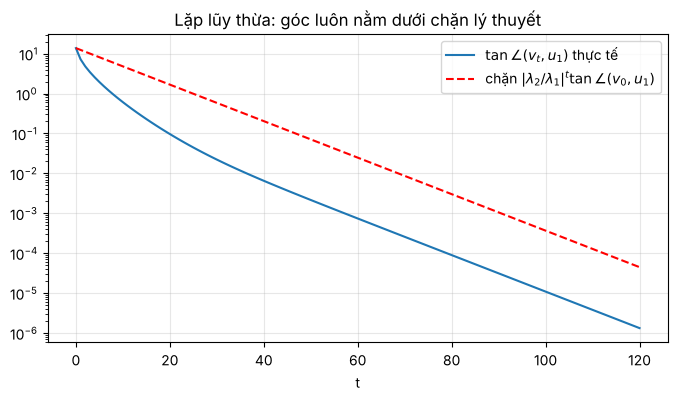

Vi phạm chặn ở bước nào? []


In [6]:
# Kiểm chứng B.5
rng = np.random.default_rng(SEED)
d = 200
Q, _ = np.linalg.qr(rng.standard_normal((d, d)))
lams = np.concatenate([[1.0, -0.9], rng.uniform(-0.85, 0.85, d - 2)])     # |lambda_2/lambda_1| = 0.9
A = (Q * lams) @ Q.T
u1 = Q[:, 0]
tan = lambda v: np.linalg.norm(v - (u1 @ v) * u1) / abs(u1 @ v)
v = rng.standard_normal(d); v /= np.linalg.norm(v)
t0 = tan(v); tans = [t0]
for t in range(120):
    v = A @ v; v /= np.linalg.norm(v); tans.append(tan(v))
ts = np.arange(121)
plt.figure(figsize=(8, 4))
plt.semilogy(ts, tans, label=r"$\tan\angle(v_t,u_1)$ thực tế")
plt.semilogy(ts, 0.9**ts * t0, "r--", label=r"chặn $|\lambda_2/\lambda_1|^t\tan\angle(v_0,u_1)$")
plt.xlabel("t"); plt.legend(); plt.title("Lặp lũy thừa: góc luôn nằm dưới chặn lý thuyết"); plt.show()
print("Vi phạm chặn ở bước nào?", [t for t in ts if tans[t] > 0.9**t * t0 * (1 + 1e-9)])

---
## B.6 Phân phối của thống kê $T^2$ khi hiệp phương sai đã biết

**Phát biểu.** Cho $x\sim\mathcal N(\mu,\Sigma)$ với $\mu$, $\Sigma$ đã biết; $\Sigma=\sum_i\lambda_iv_iv_i^\top$ ($\lambda_1\ge\dots\ge\lambda_d$, $v_i$ trực chuẩn) và $\lambda_k>0$. Đặt $t_i=v_i^\top(x-\mu)$ là tọa độ chiếu lên thành phần chính thứ $i$. Khi đó
$$T^2=\sum_{i=1}^k\frac{t_i^2}{\lambda_i}\sim\chi^2_k .$$

**Chứng minh.** Đặt $t=V_k^\top(x-\mu)\in\mathbb R^k$. Là ảnh tuyến tính của vector Gauss, $t$ có phân phối Gauss với trung bình $V_k^\top\mathbb E(x-\mu)=0$ và hiệp phương sai $V_k^\top\Sigma V_k=\Lambda_k=\operatorname{diag}(\lambda_1,\dots,\lambda_k)$ (do $\Sigma v_i=\lambda_iv_i$ và $v_i$ trực chuẩn). Đặt $z_i=t_i/\sqrt{\lambda_i}$ (được vì $\lambda_i\ge\lambda_k>0$): $z=\Lambda_k^{-1/2}t\sim\mathcal N(0,I_k)$. Với vector Gauss, không tương quan tương đương độc lập, nên $z_1,\dots,z_k$ i.i.d. $\mathcal N(0,1)$. Theo định nghĩa phân phối chi bình phương, $T^2=\sum_{i\le k}z_i^2\sim\chi^2_k$. $\blacksquare$

*Hệ quả.*
- Giới hạn kiểm soát $T^2_\alpha=\chi^2_{k,1-\alpha}$ cho đúng tỉ lệ báo động giả $\alpha$.
- Cùng lập luận: $\mathrm{SPE}=\sum_{i>k}t_i^2=\sum_{i>k}\lambda_iz_i^2$ là **tổng có trọng số của các $\chi^2_1$** — không có dạng đóng đơn giản, nên cần các xấp xỉ Jackson–Mudholkar hay Box ($g\chi^2_h$, khớp hai mômen đầu: $\mathbb E=\theta_1$, $\operatorname{Var}=2\theta_2$) dùng ở A.4.
- Khi $\mu$, $\Sigma$ **ước lượng** từ $n$ mẫu, $T^2$ của quan sát mới tuân theo $\frac{k(n-1)(n+1)}{n(n-k)}F_{k,n-k}$ (không chứng minh ở đây); với $n$ nhỏ, dùng $\chi^2_k$ sẽ làm tăng báo động giả — kiểm chứng bên dưới.

KS: T^2 ~ chi2_3: p-value = 0.684
P[T^2 > chi2_(k,0.99)] = 0.0100  (lý thuyết 0.01)
n = 30 mẫu huấn luyện: báo động giả với giới hạn chi2 = 0.0166 ± 0.0078 | với giới hạn F = 0.0037 ± 0.0025


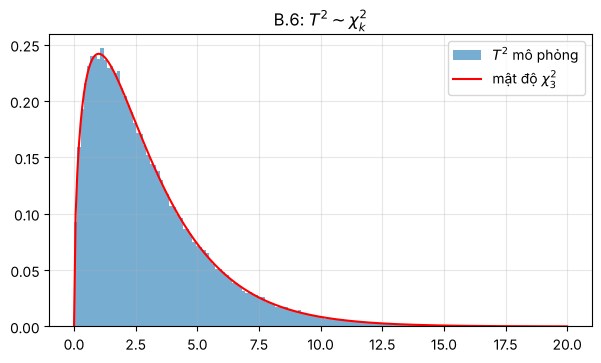

In [7]:
# Kiểm chứng B.6
rng = np.random.default_rng(SEED)
d, k, N = 10, 3, 200_000
M = rng.standard_normal((d, d)); Sig = M @ M.T / d; mu = rng.standard_normal(d)
lam, V = np.linalg.eigh(Sig); lam, V = lam[::-1], V[:, ::-1]
X = rng.multivariate_normal(mu, Sig, size=N)
T = (X - mu) @ V[:, :k]
T2 = (T**2 / lam[:k]).sum(1)
print(f"KS: T^2 ~ chi2_{k}: p-value = {stats.kstest(T2, 'chi2', args=(k,)).pvalue:.3f}")
print(f"P[T^2 > chi2_(k,0.99)] = {np.mean(T2 > stats.chi2.ppf(0.99, k)):.4f}  (lý thuyết 0.01)")

fa_chi2, fa_F = [], []
for r in range(N_RUNS):                      # hiệp phương sai ước lượng từ n = 30 mẫu
    g = np.random.default_rng(SEED + r)
    mon = PCAMonitor(k=k, alpha=0.01).fit(g.multivariate_normal(mu, Sig, size=30))
    T2n, _ = mon.scores(g.multivariate_normal(mu, Sig, size=20000))
    fa_chi2.append(np.mean(T2n > mon.T2_lim_chi2_)); fa_F.append(np.mean(T2n > mon.T2_lim_F_))
print(f"n = 30 mẫu huấn luyện: báo động giả với giới hạn chi2 = {mean_std(fa_chi2, '.4f')} | với giới hạn F = {mean_std(fa_F, '.4f')}")

xs = np.linspace(0, 20, 300)
plt.figure(figsize=(7, 3.8))
plt.hist(T2, bins=150, density=True, alpha=0.6, range=(0, 20), label=r"$T^2$ mô phỏng")
plt.plot(xs, stats.chi2.pdf(xs, k), "r", label=rf"mật độ $\chi^2_{k}$")
plt.legend(); plt.title(r"B.6: $T^2\sim\chi^2_k$"); plt.show()